# Was ist bei Brustkrebs anders?

**Brustkrebs** ist die häufigste Krebsart bei Frauen. Im Projekt **The Cancer Genome Atlas (TCGA)** haben Forschende die Tumoren von über 1.000 Patientinnen sequenziert, und bei einigen auch **normales Brustgewebe** aus der Nähe des Tumors. Alle diese Daten sind öffentlich.

Du bekommst die Daten von **10 Patientinnen**: von jeder eine Probe aus dem Tumor und eine aus normalem Gewebe, also **20 Proben**. Anders als Mäuse oder Zellen im Labor sind das echte Menschen verschiedenen Alters mit verschiedenen Arten von Tumoren. Rechne damit, dass die Daten unordentlicher sind!

### Deine Forschungsfrage

> Welche Gene unterscheiden sich zwischen Brusttumoren und normalem Brustgewebe derselben Patientinnen? Was verraten sie darüber, was Krebszellen tun?

Der Datensatz heißt `"cancer"`.

In [1]:
setLanguage("de")   # Sprache der Ausgaben und Grafiken

Sprache: Deutsch



In [2]:
data <- loadDataset("cancer")
data$samples

Datensatz 'cancer' geladen: 19944 Gene, 20 Proben.



,sample,patient,tissue
,<chr>,<fct>,<fct>
A7_A0CE_normal,A7_A0CE_normal,A7_A0CE,normal
A7_A0CH_normal,A7_A0CH_normal,A7_A0CH,normal
A7_A0D9_normal,A7_A0D9_normal,A7_A0D9,normal
A7_A13F_normal,A7_A13F_normal,A7_A13F,normal
AC_A23H_normal,AC_A23H_normal,AC_A23H,normal
AC_A2FB_normal,AC_A2FB_normal,AC_A2FB,normal
AC_A2FF_normal,AC_A2FF_normal,AC_A2FF,normal
AC_A2FM_normal,AC_A2FM_normal,AC_A2FM,normal
BH_A0AU_normal,BH_A0AU_normal,BH_A0AU,normal


### Deine Schritte

Gehe dieselben Schritte wie im Tutorial durch. Du kannst Code aus `01_tutorial_milk.ipynb` kopieren und anpassen: Die **Spaltennamen** und **Gruppennamen** sind hier anders. Unter jedem Schritt gibt es eine Zelle für deinen Code und einen Tipp, den du öffnen kannst, wenn du nicht weiterkommst.

| Schritt | Funktionen aus dem Tutorial |
|---|---|
| 1 Daten ansehen | `DGEList`, `plotLibrarySizes` |
| 2 Gruppen festlegen | `dge$samples$group <- …`, `table`, `plotGene` |
| 3 Vorbereiten | `filterByExpr`, `normLibSizes`, `plotDistributions`, `plotSamples` |
| 4 Design und Kontrast | `model.matrix`, `makeContrasts` |
| 5 Testen | `voom`, `lmFit`, `contrasts.fit`, `eBayes`, `decideTests` |
| 6 Deuten | `plotVolcano`, `showTop`, `plotGene` |

Wenn eine Zelle einen Fehler meldet: Lies die Meldung, prüfe die Schreibweise der Namen und ob du die Zellen darüber ausgeführt hast.

## 1 Daten ansehen

Erstelle eine `DGEList` und sieh dir die Bibliotheksgrößen an.

[1] 19944    20

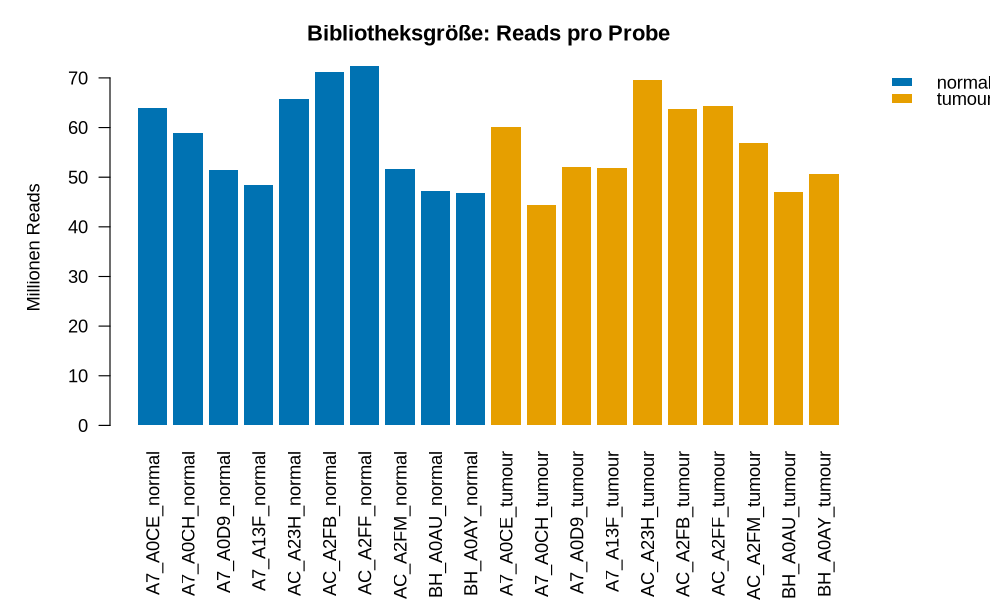

In [3]:
dge <- DGEList(counts = data$counts, samples = data$samples, genes = data$genes)
dim(dge)
plotLibrarySizes(dge, colour_by = "tissue")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Wie im Tutorial. Färbe nach `"tissue"`.

</details>

## 2 Gruppen festlegen

Lege die Gruppen fest (Spalte `tissue`). Sieh dir dann ein Gen an, das jedes wachsende Gewebe braucht: **MKI67** wird nur von Zellen hergestellt, die sich **teilen**.


normal tumour 
    10     10 

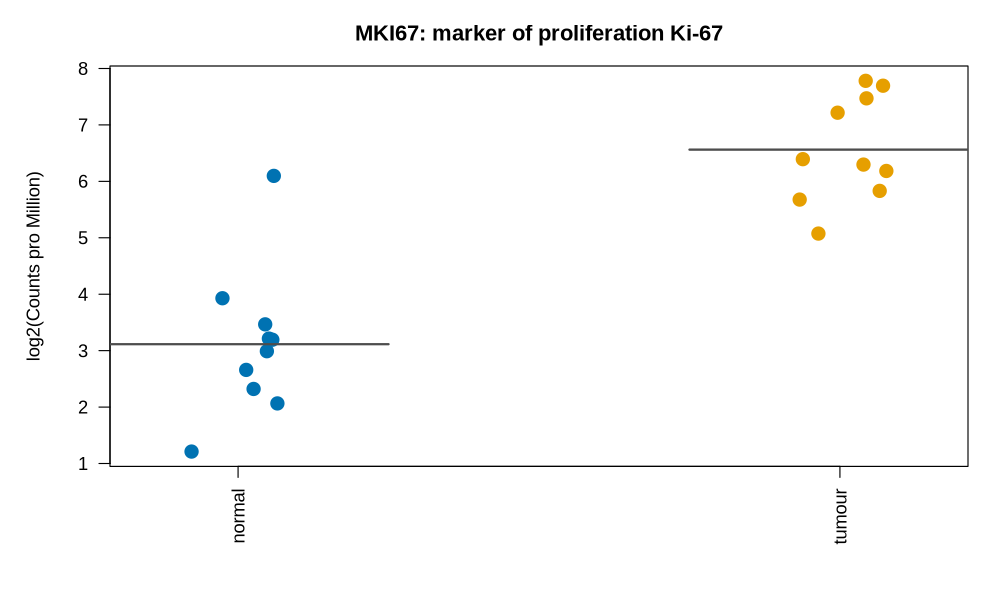

In [4]:
dge$samples$group <- dge$samples$tissue
table(dge$samples$group)
plotGene(dge, "MKI67", group_by = "tissue")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

`dge$samples$group <- dge$samples$tissue`, dann `plotGene(dge, "MKI67", group_by = "tissue")`.

</details>

## 3 Vorbereiten

Filtere, normalisiere und zeichne die Probenkarte, gefärbt nach Gewebe und beschriftet mit der Patientin.

[1] 15580    20

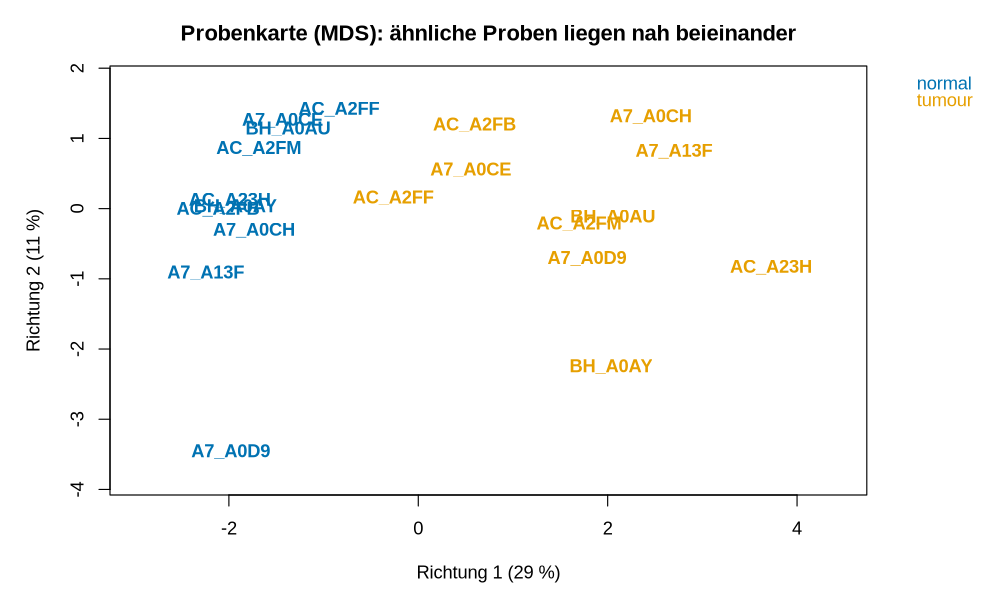

In [5]:
keep <- filterByExpr(dge)
dge <- dge[keep, , keep.lib.sizes = FALSE]
dge <- normLibSizes(dge)
dim(dge)
plotSamples(dge, colour_by = "tissue", label_by = "patient")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Wie Teil 3 des Tutorials, mit `plotSamples(dge, colour_by = "tissue", label_by = "patient")`.

</details>

**Frage: Sind die normalen Proben und die Tumorproben getrennt? Welche Gruppe ist stärker verstreut, und woran könnte das liegen?**

✅ **Antwort:** Richtung 1 (29 %) trennt überwiegend **normales Gewebe (links)** von **Tumoren (rechts)**. Die normalen Proben liegen nah beieinander, die Tumoren sind weit verstreut: Jeder Tumor ist anders (andere Mutationen, andere Arten von Brustkrebs). Ein Tumor (AC_A2FF) liegt nah bei den normalen Proben; vielleicht enthält er viel normales Gewebe.

## 4 Design und Kontrast

Jede Patientin hat eine Tumor- **und** eine Normalprobe geliefert: Was für ein Experiment ist das? Denk daran, was du über **gepaarte** Designs weißt (oder lies den Tipp), und schreibe dann das Design und den Kontrast `tumour_vs_normal`.

In [6]:
design <- model.matrix(~0 + tissue + patient, data = dge$samples)
colnames(design)
contrasts <- makeContrasts(tumour_vs_normal = tissuetumour - tissuenormal, levels = design)

[1] "tissuenormal"   "tissuetumour"   "patientA7_A0CH" "patientA7_A0D9" "patientA7_A13F" "patientAC_A23H"
 [7] "patientAC_A2FB" "patientAC_A2FF" "patientAC_A2FM" "patientBH_A0AU" "patientBH_A0AY"

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Ein gepaartes Design: Nimm die Patientin ins Design auf, damit jeder Tumor mit dem Normalgewebe **derselben** Patientin verglichen wird: `model.matrix(~0 + tissue + patient, data = dge$samples)`. Der Kontrast benutzt die Spalten `tissuetumour` und `tissuenormal`.

</details>

## 5 Testen

Teste jedes Gen und zähle die signifikanten.

       tumour_vs_normal
Down               2352
NotSig            11146
Up                 2082

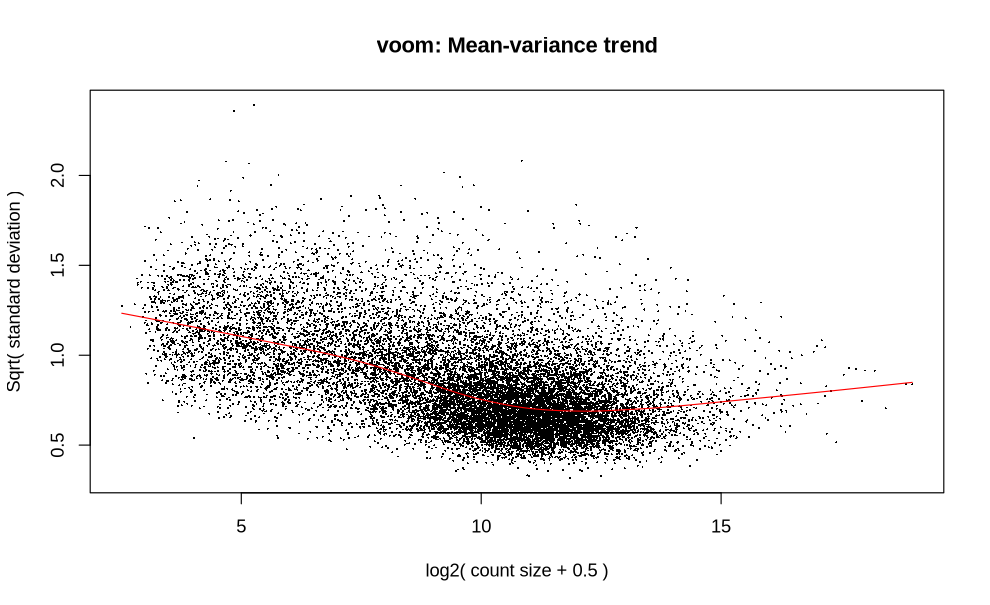

In [7]:
v <- voom(dge, design, plot = TRUE)
fit <- lmFit(v, design)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)
summary(decideTests(fit))

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Die Zellen aus Teil 5 des Tutorials funktionieren unverändert.

</details>

**Frage: Wie viele Gene sind signifikant? Ist das eine Liste, die man noch durchlesen kann?**

✅ **Antwort:** Etwa **2.100 hoch** und **2.350 runter**: viel zu viele zum Durchlesen. Wir müssen **Prioritäten setzen**: zuerst die stärksten Veränderungen ansehen (Vulkan-Plot, `showTop`) oder nach Genen fragen, die sich sehr stark ändern (siehe Bonus).

## 6 Deuten

Zeichne den Vulkan-Plot und liste die Top-Gene auf, die hoch und runter gehen. Schlage einige auf [GeneCards](https://www.genecards.org) nach. Versuche, sie in ein paar **Themen** zu sortieren.

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
COL10A1,collagen type X alpha 1 chain,7.15,142.4× höher,3.1,8.8e-06
SLC24A2,solute carrier family 24 member 2,5.83,56.9× höher,-1.2,3.1e-05
TNNT1,"troponin T1, slow skeletal type",4.57,23.8× höher,1.3,8.8e-05
NUF2,NUF2 component of NDC80 kinetochore complex,3.22,9.3× höher,1.8,9.3e-05
MMP11,matrix metallopeptidase 11,5.28,38.8× höher,5.2,9.3e-05
ERCC6L,"ERCC excision repair 6 like, spindle assemb…",3.02,8.1× höher,1.2,9.3e-05
ASPM,assembly factor for spindle microtubules,3.86,14.5× höher,2.7,9.4e-05
RAMP1,receptor activity modifying protein 1,3.56,11.8× höher,2.9,9.4e-05
INHBA,inhibin subunit beta A,3.82,14.1× höher,4.3,9.4e-05


symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
JPH2,junctophilin 2,-3.42,10.7× niedriger,3.4,2.3e-05
FGF1,fibroblast growth factor 1,-2.43,5.4× niedriger,4.9,2.7e-05
MME,membrane metalloendopeptidase,-3.91,15.1× niedriger,5.9,3.1e-05
HPSE2,heparanase 2 (inactive),-4.33,20.1× niedriger,1.4,6.0e-05
PAMR1,peptidase domain containing associated with…,-4.23,18.7× niedriger,4.2,6.0e-05
LRRC3B,leucine rich repeat containing 3B,-4.52,23.0× niedriger,-1.2,7.7e-05
SCGB3A1,secretoglobin family 3A member 1,-4.87,29.2× niedriger,1.7,8.3e-05
KLHL29,kelch like family member 29,-2.97,7.8× niedriger,3.3,8.3e-05
APCDD1L,APC down-regulated 1 like,-3.29,9.8× niedriger,2.1,8.3e-05


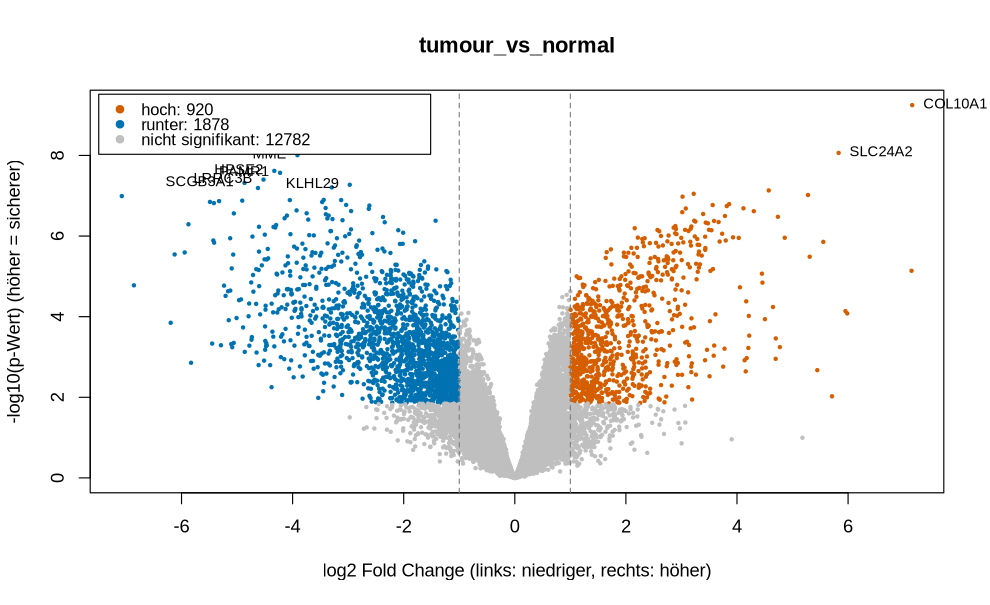

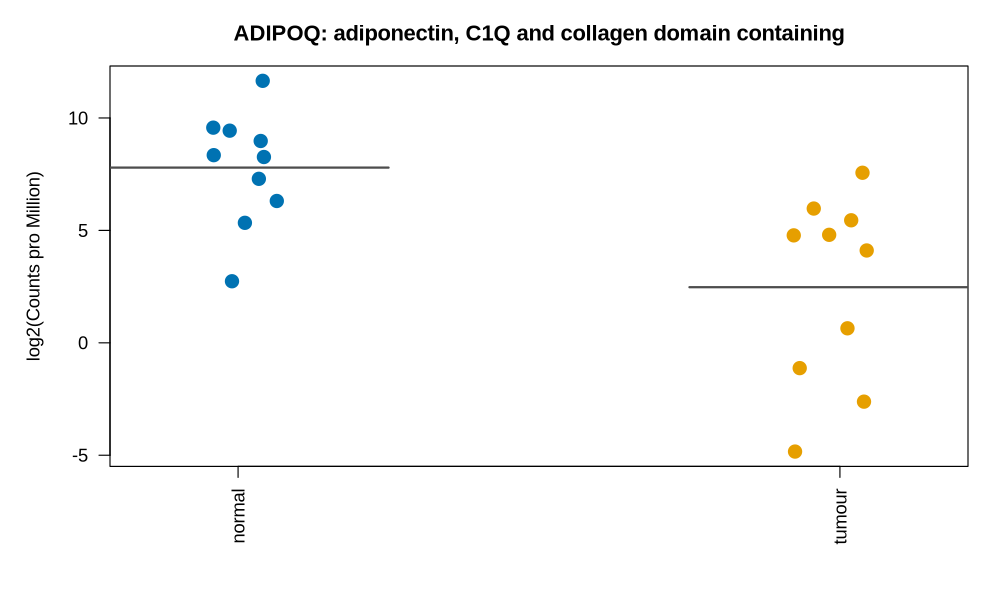

In [8]:
plotVolcano(fit, "tumour_vs_normal")
showTop(fit, "tumour_vs_normal", n = 20, direction = "up")
showTop(fit, "tumour_vs_normal", n = 20, direction = "down")
plotGene(dge, "ADIPOQ", group_by = "tissue")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Mögliche Themen: **Zellteilung** (achte auf Kinesine *KIF…*, *ASPM*, *NUF2*, *NEK2*, *TOP2A*), **Umbau des Gewebes um den Tumor** (Kollagene *COL…*, Matrix-Metalloproteinasen *MMP…*), und auf der „runter“-Seite: Woraus besteht normales Brustgewebe vor allem? Probiere `plotGene` mit **ADIPOQ** und **LEP**.

</details>

## Dein Fazit

Beantworte die Forschungsfrage in ein paar Sätzen: Was hast du verglichen, was hast du gefunden, und was bedeutet es? Sei bereit, deinen Vulkan-Plot und deine Antwort der Klasse zu zeigen.

✅ **Antwort:** Wir haben Tumor- und normales Brustgewebe von 10 Patientinnen mit einem gepaarten Design verglichen. Etwa 2.100 Gene gingen hoch und 2.350 runter. Hoch: viele Gene für die **Zellteilung** (*NUF2*, *ASPM*, *KIF4A*, *NEK2*, *MKI67*, *TOP2A*): Krebszellen teilen sich unkontrolliert. Außerdem hoch: Gene, die das **Gewebe um den Tumor umbauen** (*COL10A1*, *MMP11*, *INHBA*), was Tumoren beim Wachsen und Eindringen hilft. Runter: Gene des **Fettgewebes** (*ADIPOQ*, *LEP*), weil normales Brustgewebe größtenteils aus Fett besteht und der Tumor es verdrängt, und Gene der normalen Milchgänge (*SCGB3A1*, *MME*). Gene wie *ESR1* (Östrogenrezeptor) und *ERBB2* (HER2) unterscheiden sich stark zwischen den Patientinnen: Brustkrebs ist nicht eine einzige Krankheit, deshalb wird die Behandlung für jede Patientin einzeln ausgewählt.

## Bonus 1: Nur die großen Veränderungen

Bei Tausenden signifikanten Genen kannst du eine strengere Frage stellen: Welche Gene ändern sich **mindestens 4-fach** (log Fold Change von 2)? `treat` testet genau das.

In [9]:
fit_strict <- treat(fit, lfc = 2)
summary(decideTests(fit_strict))
showTop(fit_strict, "tumour_vs_normal", n = 30)

       tumour_vs_normal
Down                 20
NotSig            15552
Up                    8

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
COL10A1,collagen type X alpha 1 chain,7.15,142.4× höher,3.1,0.00023
SLC24A2,solute carrier family 24 member 2,5.83,56.9× höher,-1.2,0.00440
SMYD1,SET and MYND domain containing 1,-7.07,134.8× niedriger,0.5,0.01100
SCGB3A1,secretoglobin family 3A member 1,-4.87,29.2× niedriger,1.7,0.01900
MMP11,matrix metallopeptidase 11,5.28,38.8× höher,5.2,0.01900
VEGFD,vascular endothelial growth factor D,-5.49,44.9× niedriger,2.4,0.01900
OXTR,oxytocin receptor,-5.42,42.7× niedriger,4.9,0.01900
FABP7,fatty acid binding protein 7,-5.32,40.0× niedriger,0.1,0.01900
HPSE2,heparanase 2 (inactive),-4.33,20.1× niedriger,1.4,0.01900


## Bonus 2: Jeder Tumor ist anders

Sieh dir **ESR1** (den Östrogenrezeptor) und **ERBB2** (HER2) mit `plotGene` an. Ärztinnen und Ärzte testen diese beiden bei jedem Brusttumor. Was siehst du?

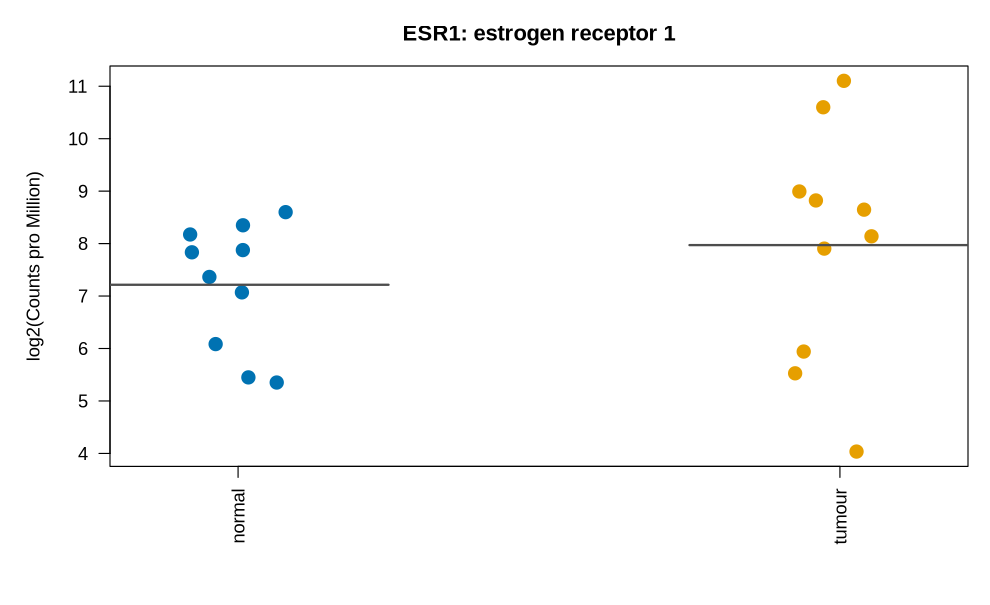

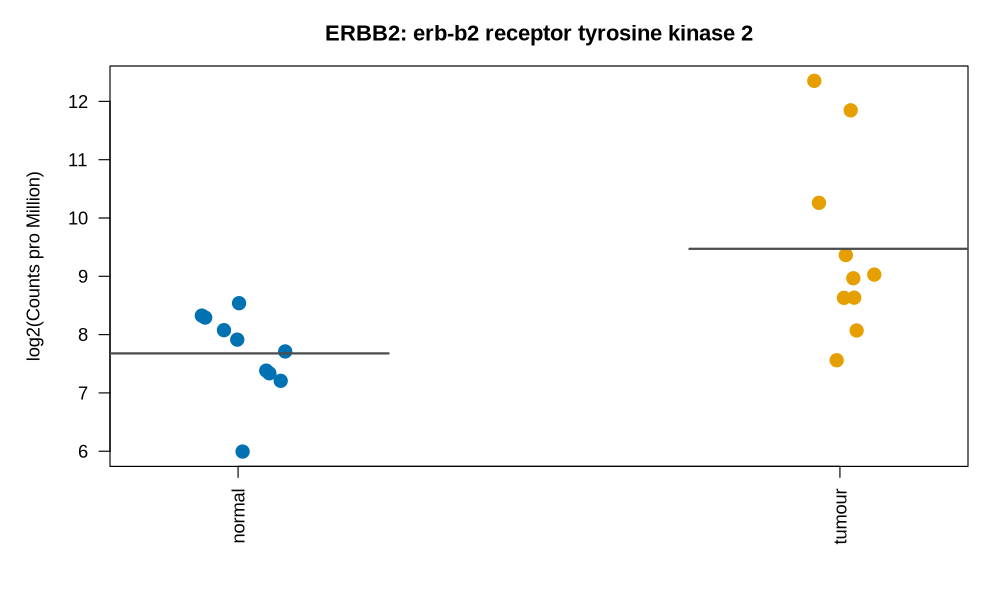

In [10]:
plotGene(dge, "ESR1", group_by = "tissue")
plotGene(dge, "ERBB2", group_by = "tissue")

✅ **Antwort:** Mit `treat` bleiben nur etwa **28** Gene übrig: eine kurze Liste der größten Veränderungen. ESR1 ist in manchen Tumoren hoch und in anderen sehr niedrig; im Mittel gibt es keinen signifikanten Unterschied. ERBB2 ist nur in wenigen Tumoren sehr hoch. Diese Patientinnen haben verschiedene **Arten** von Brustkrebs: Östrogenrezeptor-positive Tumoren lassen sich mit Anti-Hormon-Medikamenten behandeln, HER2-positive mit Antikörpern gegen HER2. Ein Vergleich von Mittelwerten kann solche Unterschiede zwischen Patientinnen verdecken.

<small>Software: limma (Ritchie et al. 2015) mit voom (Law et al. 2014) und edgeR (Chen et al. 2025) in R. Vollständige Quellen aller Datensätze am Ende von `01_tutorial_milk.ipynb`.</small>